In [25]:
from pathlib import Path
import random

import numpy as np
import torch
from torch.utils.data import DataLoader

SEED = 42

# Fix random seeds to make experiments more reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Normal device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set paths for files
project_dir = Path.cwd()
data_dir = project_dir / "data" / "keras_slices_data"
checkpoint_dir = project_dir / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)

# Setup constants
NUM_CLASSES = 6
PROSTATE_LABEL = 5 # Other labels can be found in dataset notebook
BATCH_SIZE = 16
# Value chosen after initial training split showed progress slowed after around 20 epochs.
# Also lines up with ~1h of training time for training restriction (A100 GPU)
EPOCHS = 20 

LEARNING_RATE = 1e-3

print("Device:", device)
print("Dataset:", data_dir)
print("Prostate label:", PROSTATE_LABEL)

Device: cuda
Dataset: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/data/keras_slices_data
Prostate label: 5


Split           Pairs   Patients
train           11460         31
validate          660          4
test              540          3
All image–mask pairs matched; no patient overlap.
Example: case_004_week_0_slice_0.nii.gz
Image: (256, 128) float32
Mask: (256, 128) int64
Normalised image mean: 0.0
Normalised image standard deviation: 1.0
Mask labels: [0 1 2 3]
Documentation files:
No documentation found beside the uploaded dataset.
Description: b''
Auxiliary information: b''
Extensions: Nifti1Extensions()
Training slices: 11460
Image batch: (16, 1, 256, 144) torch.float32
Mask batch: (16, 256, 144) torch.int64
Labels in this batch: [-100, 0, 1, 2, 3, 4, 5]


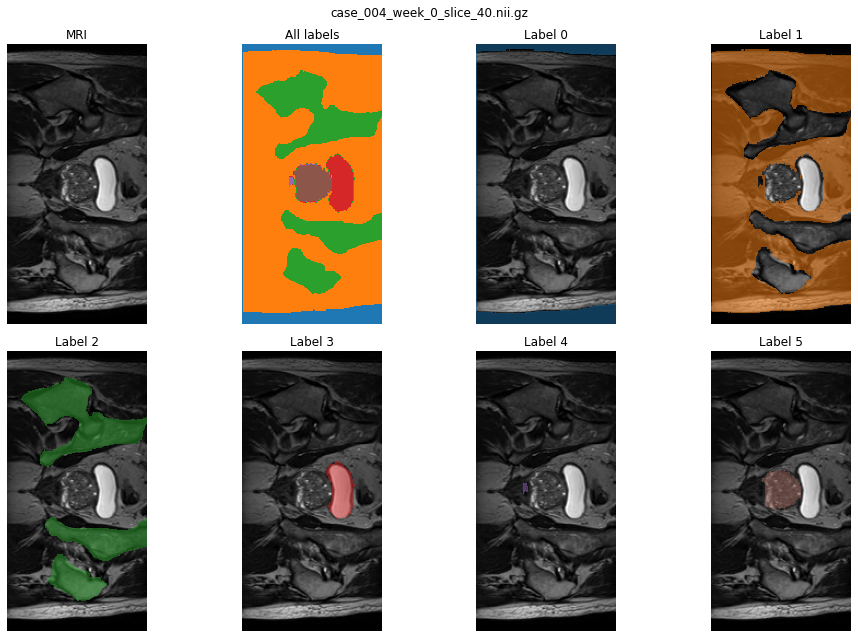

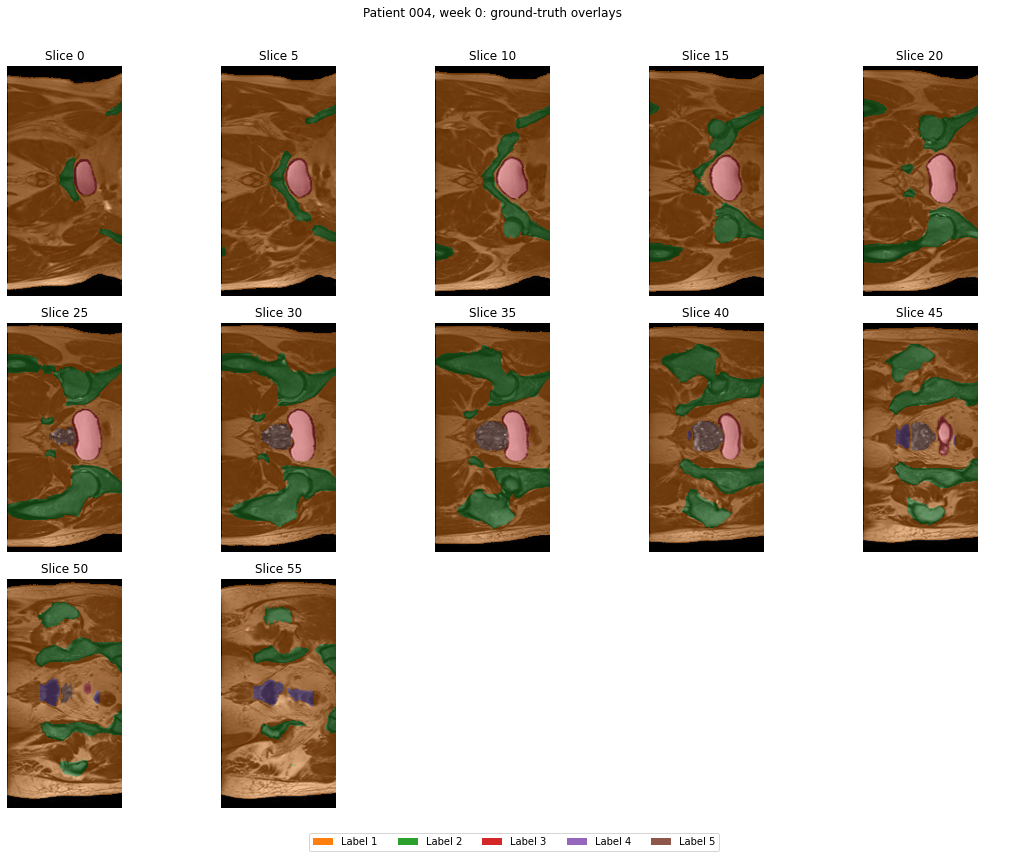

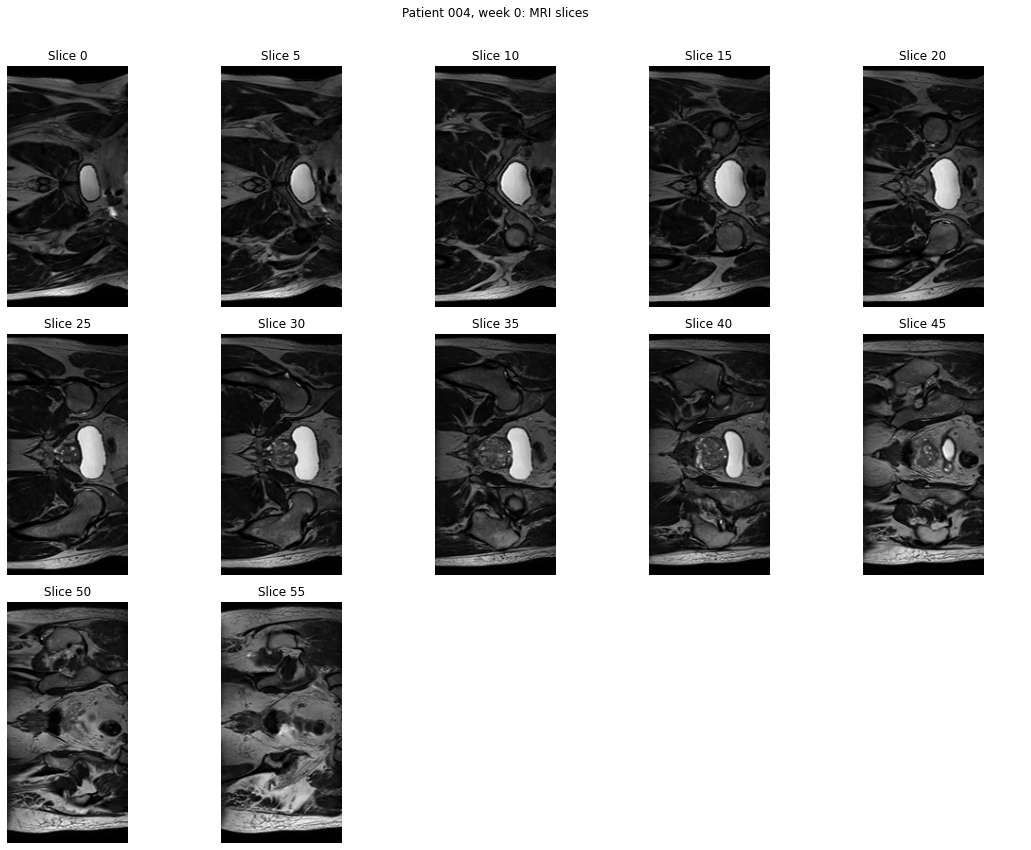

Device: cuda
Input shape: (16, 1, 256, 128)
Output shape: (16, 6, 256, 128)
Parameters: 2,158,502


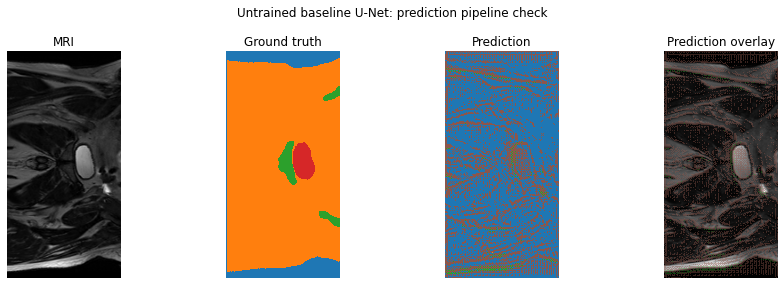

In [26]:
# Run dataset definitions and checks in this notebook's kernel.
%run ./dataset.ipynb

# Run the baseline architecture definitions.
%run ./modules.ipynb

In [27]:
# Re-establish settings after running the dataset and modules notebooks
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

data_dir = project_dir / "data" / "keras_slices_data"
splits = audit_splits(data_dir)

# Data loaders
# Shuffle only training data
train_loader = DataLoader(
    HipMRIDataset(splits["train"]),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    HipMRIDataset(splits["validate"]),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# Create fresh baseline
model = UNet(classes=NUM_CLASSES, base=16).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = torch.nn.CrossEntropyLoss(ignore_index=-100)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Prostate class:", PROSTATE_LABEL)

Split           Pairs   Patients
train           11460         31
validate          660          4
test              540          3
All image–mask pairs matched; no patient overlap.
Training batches: 717
Validation batches: 42
Prostate class: 5


In [28]:
# Train the baseline
history = []
best_dice = -1.0

checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "baseline_best.pt"
history_path = checkpoint_dir / "baseline_history.csv"

# Start the clock measuring time budget for the training
TIME_LIMIT_SECONDS = 60 * 60
training_start = time.perf_counter()

# Track peak PyTorch GPU memory during training and validation.
if device.type == "cuda":
    torch.cuda.synchronize(device)
    torch.cuda.reset_peak_memory_stats(device)

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_dice = run_epoch(
        model, train_loader, training=True
    )
    val_loss, val_dice = run_epoch(
        model, val_loader, training=False
    )

    seconds = time.perf_counter() - start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_prostate_dice": train_dice,
        "val_prostate_dice": val_dice,
        "seconds": seconds,
    })

    # Save the history before checking whether to stop.
    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_dice > best_dice:
        best_dice = val_dice

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_prostate_dice": val_dice,
            "num_classes": NUM_CLASSES,
            "prostate_label": PROSTATE_LABEL,
            "base": 16,
            "target_size": (256, 144),
            "model_type": "baseline",
        }, checkpoint_path)

    elapsed = time.perf_counter() - training_start

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"loss {train_loss:.4f} / {val_loss:.4f} | "
        f"prostate Dice {train_dice:.4f} / {val_dice:.4f} | "
        f"{seconds:.1f}s | best val {best_dice:.4f} | "
        f"elapsed {elapsed / 60:.1f} min",
        flush=True,
    )

    # Stop cleanly after finishing and recording the current epoch.
    if elapsed >= TIME_LIMIT_SECONDS:
        print("One-hour training limit reached. Stopping.")
        break

if device.type == "cuda":
    print(
        "Training/validation peak allocated VRAM:",
        f"{torch.cuda.max_memory_allocated(device) / 1024**3:.3f} GiB"
    )
    print(
        "Training/validation peak reserved VRAM:",
        f"{torch.cuda.max_memory_reserved(device) / 1024**3:.3f} GiB"
    )

print("Best checkpoint:", checkpoint_path)

Epoch 01/20 | loss 0.2285 / 0.1046 | prostate Dice 0.2869 / 0.6847 | 132.2s | best val 0.6847 | elapsed 2.2 min


Epoch 02/20 | loss 0.0611 / 0.0815 | prostate Dice 0.8221 / 0.7907 | 130.4s | best val 0.7907 | elapsed 4.4 min


Epoch 03/20 | loss 0.0506 / 0.0788 | prostate Dice 0.8589 / 0.7782 | 128.3s | best val 0.7907 | elapsed 6.5 min


Epoch 04/20 | loss 0.0477 / 0.0672 | prostate Dice 0.8717 / 0.8078 | 129.1s | best val 0.8078 | elapsed 8.7 min


Epoch 05/20 | loss 0.0431 / 0.0802 | prostate Dice 0.8861 / 0.8231 | 133.6s | best val 0.8231 | elapsed 10.9 min


...

Epoch 16/20 | loss 0.0402 / 0.0819 | prostate Dice 0.8908 / 0.8189 | 123.3s | best val 0.8231 | elapsed 34.5 min


Epoch 17/20 | loss 0.0406 / 0.0737 | prostate Dice 0.8919 / 0.8224 | 124.0s | best val 0.8231 | elapsed 36.6 min


Epoch 18/20 | loss 0.0376 / 0.0711 | prostate Dice 0.8987 / 0.8259 | 130.5s | best val 0.8259 | elapsed 38.8 min


Epoch 19/20 | loss 0.0405 / 0.0758 | prostate Dice 0.8919 / 0.7929 | 127.7s | best val 0.8259 | elapsed 40.9 min


Epoch 20/20 | loss 0.0390 / 0.0761 | prostate Dice 0.8941 / 0.8304 | 128.6s | best val 0.8304 | elapsed 43.1 min
Training/validation peak allocated VRAM: 0.727 GiB
Training/validation peak reserved VRAM: 0.906 GiB
Best checkpoint: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/baseline_best.pt


In [ ]:
# Epoch 20/20 | loss 0.0390 / 0.0761 | prostate Dice 0.8941 / 0.8304 | 128.6s | best val 0.8304 | elapsed 43.1 min
# Training/validation peak allocated VRAM: 0.727 GiB
#Training/validation peak reserved VRAM: 0.906 GiB
# Best checkpoint: /lambda/nfs/comp3710-virginia/PatternAnalysis-2026/recognition/ResidualUNet_s4749642/checkpoints/baseline_best.pt